In [40]:
import pandas as pd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, classification_report, confusion_matrix,recall_score

In [41]:
pip install pandas numpy seaborn matplotlib scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


A. Conduct an Exploratory Data Analysis (EDA) on the dataset. 
Highlight the main insights and any irregularities you find, and address those anomalies appropriately!

In [42]:
df = pd.read_csv("Credis_Score_Dataset_A.csv")
df.head(5)

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x113fb,CUS_0x78af,February,Greg Roumeliotisg,36,365-11-8309,Teacher,88827.54000000002,7199.295000,5,...,Standard,512.09,27.652902,11 Years and 3 Months,Yes,277.043609,135.02877621323586,!@9#%8,567.8571148175499,Standard
1,0x23e41,CUS_0x7d8,April,Ayla Jeany,14_,680-85-5010,Doctor,19288.47_,1408.372500,10,...,Bad,1873.07,28.477331,5 Years and 7 Months,Yes,49.388699,176.92086141687474,Low_spent_Small_value_payments,204.52768958953004,Poor
2,0x20142,CUS_0x39d4,January,Debra Shermanh,45,034-42-6069,Accountant,73507.4,6146.616667,8,...,Bad,1660.98,24.865827,15 Years and 7 Months,Yes,412.051367,186.58955671354923,High_spent_Medium_value_payments,266.02074289372644,Poor
3,0xd194,CUS_0x8ac8,July,Steve Schererz,22,751-26-7144,Teacher,10037.735,871.477917,8,...,Bad,3052.44,33.704571,8 Years and 1 Months,Yes,36.667662,16.69811395620942,High_spent_Medium_value_payments,283.7820159487275,Standard
4,0x64dc,CUS_0x6734,March,Lefterisi,19,276-02-5954,_______,30922.5,2477.875000,8,...,Bad,4742.53,30.643675,1 Years and 0 Months,Yes,165.891821,218.49777601292416,Low_spent_Small_value_payments,153.39790325798555,Standard


In [43]:
df.columns

Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [44]:
df.isnull().sum()

ID                             0
Customer_ID                    0
Month                          0
Name                        5043
Age                            0
SSN                            0
Occupation                     0
Annual_Income                  0
Monthly_Inhand_Salary       7514
Num_Bank_Accounts              0
Num_Credit_Card                0
Interest_Rate                  0
Num_of_Loan                    0
Type_of_Loan                5732
Delay_from_due_date            0
Num_of_Delayed_Payment      3400
Changed_Credit_Limit           0
Num_Credit_Inquiries         958
Credit_Mix                     0
Outstanding_Debt               0
Credit_Utilization_Ratio       0
Credit_History_Age          4566
Payment_of_Min_Amount          0
Total_EMI_per_month            0
Amount_invested_monthly     2252
Payment_Behaviour              0
Monthly_Balance              589
Credit_Score                   0
dtype: int64

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  object 
 1   Customer_ID               50000 non-null  object 
 2   Month                     50000 non-null  object 
 3   Name                      44957 non-null  object 
 4   Age                       50000 non-null  object 
 5   SSN                       50000 non-null  object 
 6   Occupation                50000 non-null  object 
 7   Annual_Income             50000 non-null  object 
 8   Monthly_Inhand_Salary     42486 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  object 
 13  Type_of_Loan              44268 non-null  object 
 14  Delay_

In [46]:
df['Name'].value_counts


<bound method IndexOpsMixin.value_counts of 0        Greg Roumeliotisg
1               Ayla Jeany
2           Debra Shermanh
3           Steve Schererz
4                Lefterisi
               ...        
49995        Adrian Croftf
49996                Lisam
49997              Alexeit
49998               Whitew
49999                Bradm
Name: Name, Length: 50000, dtype: object>

In [47]:
df['Monthly_Inhand_Salary'].value_counts

<bound method IndexOpsMixin.value_counts of 0         7199.295000
1         1408.372500
2         6146.616667
3          871.477917
4         2477.875000
             ...     
49995     1790.069583
49996    10558.013333
49997      508.555000
49998      741.082500
49999     3662.030000
Name: Monthly_Inhand_Salary, Length: 50000, dtype: float64>

In [48]:
df['Type_of_Loan'].value_counts 

<bound method IndexOpsMixin.value_counts of 0        Mortgage Loan, Mortgage Loan, Auto Loan, and P...
1        Payday Loan, Not Specified, Student Loan, Home...
2        Mortgage Loan, Student Loan, Credit-Builder Lo...
3        Mortgage Loan, Mortgage Loan, Not Specified, D...
4        Auto Loan, Payday Loan, Not Specified, Persona...
                               ...                        
49995    Debt Consolidation Loan, Credit-Builder Loan, ...
49996                                                  NaN
49997    Debt Consolidation Loan, Payday Loan, Home Equ...
49998    Auto Loan, Credit-Builder Loan, Payday Loan, C...
49999    Not Specified, Personal Loan, and Debt Consoli...
Name: Type_of_Loan, Length: 50000, dtype: object>

In [ ]:
# Cek kolom age
# Kita cari yg bkn angka murni
umur_aneh = df[pd.to_numeric(df['Age'], errors='coerce').isna()]['Age'].unique()
print(f"-> Anomali di kolom Age (contoh 5 teratas): {umur_aneh[:5]}")

print(f"-> Anomali di Payment_Behaviour: {df['Payment_Behaviour'].unique()}")


print(f"-> Contoh format Credit_History_Age: {df['Credit_History_Age'].iloc[0]}")


#cek outlier
cols_to_check = ['Annual_Income', 'Age']
temp_df = df.copy()
for col in cols_to_check:
    temp_df[col] = pd.to_numeric(temp_df[col].astype(str).str.replace('_', ''), errors='coerce')


print(temp_df[cols_to_check].describe().loc[['min', 'max']])

# Kalau minny negatif (misal Gaji -500) anomali
# Kalau Maxny kegedean (misal Umur 500) anomali

-> Anomali di kolom Age (contoh 5 teratas): ['14_' '32_' '22_' '18_' '40_']
-> Anomali di Payment_Behaviour: ['!@9#%8' 'Low_spent_Small_value_payments'
 'High_spent_Medium_value_payments' 'Low_spent_Medium_value_payments'
 'High_spent_Small_value_payments' 'Low_spent_Large_value_payments'
 'High_spent_Large_value_payments']
-> Contoh format Credit_History_Age: 11 Years and 3 Months
     Annual_Income     Age
min        7005.93  -500.0
max    24177153.00  8698.0


In [50]:

df['Age'] = df['Age'].astype(str).str.replace('_', '')


df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

df.loc[(df['Age'] < 0) | (df['Age'] > 100), 'Age'] = np.nan


median_age = df['Age'].median()
df['Age'] = df['Age'].fillna(median_age)
print(f" Median umur sekarang: {median_age}")



def bersihkan_history(teks):
    if pd.isna(teks): 
        return np.nan 
    if isinstance(teks, str):
        cari_tahun = re.search(r'(\d+) Years', teks)
        cari_bulan = re.search(r'(\d+) Months', teks)
        

        tahun = int(cari_tahun.group(1)) if cari_tahun else 0
        bulan = int(cari_bulan.group(1)) if cari_bulan else 0
       
        total_bulan = (tahun * 12) + bulan
        return total_bulan
    return teks


df['Credit_History_Age_Months'] = df['Credit_History_Age'].apply(bersihkan_history)

df = df.drop(columns=['Credit_History_Age'])


print(df['Age'].describe())



 Median umur sekarang: 33.0
count    50000.000000
mean        33.300940
std         10.633827
min         14.000000
25%         25.000000
50%         33.000000
75%         41.000000
max         99.000000
Name: Age, dtype: float64


In [51]:
#apus yg ada '_' nya

kolom_kotor = ['Annual_Income', 'Num_of_Loan', 'Num_of_Delayed_Payment', 
               'Changed_Credit_Limit', 'Outstanding_Debt', 'Amount_invested_monthly', 
               'Monthly_Balance']

for col in kolom_kotor:
    df[col] = df[col].astype(str).str.replace('_', '')
    df[col] = pd.to_numeric(df[col], errors='coerce')
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())




In [52]:
#kalau angka isi Median,  teks isi modus.

for col in df.columns:
    if df[col].dtype in ['float64', 'int64']:
        median_value = df[col].median()
        df[col] = df[col].fillna(median_value)
    else:
        mode_value = df[col].mode()[0]
        df[col] = df[col].fillna(mode_value)
print(df.isnull().sum())



ID                           0
Customer_ID                  0
Month                        0
Name                         0
Age                          0
SSN                          0
Occupation                   0
Annual_Income                0
Monthly_Inhand_Salary        0
Num_Bank_Accounts            0
Num_Credit_Card              0
Interest_Rate                0
Num_of_Loan                  0
Type_of_Loan                 0
Delay_from_due_date          0
Num_of_Delayed_Payment       0
Changed_Credit_Limit         0
Num_Credit_Inquiries         0
Credit_Mix                   0
Outstanding_Debt             0
Credit_Utilization_Ratio     0
Payment_of_Min_Amount        0
Total_EMI_per_month          0
Amount_invested_monthly      0
Payment_Behaviour            0
Monthly_Balance              0
Credit_Score                 0
Credit_History_Age_Months    0
dtype: int64


In [53]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_summary[col] = len(outliers)

print("\nJumlah outlier per fitur (IQR):")
for k, v in outlier_summary.items():
    print(f"{k}: {v}")



Jumlah outlier per fitur (IQR):
Age: 2
Annual_Income: 1401
Monthly_Inhand_Salary: 2232
Num_Bank_Accounts: 689
Num_Credit_Card: 1092
Interest_Rate: 987
Num_of_Loan: 2234
Delay_from_due_date: 1995
Num_of_Delayed_Payment: 372
Changed_Credit_Limit: 559
Num_Credit_Inquiries: 829
Outstanding_Debt: 2650
Credit_Utilization_Ratio: 2
Total_EMI_per_month: 3369
Amount_invested_monthly: 5476
Monthly_Balance: 3912
Credit_History_Age_Months: 0


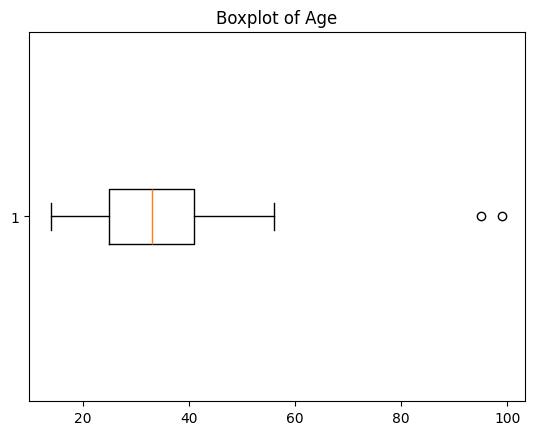

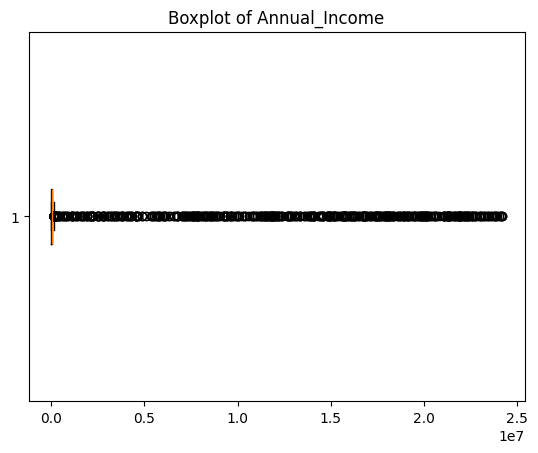

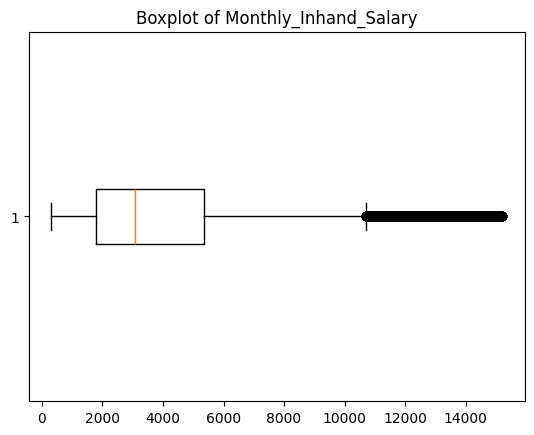

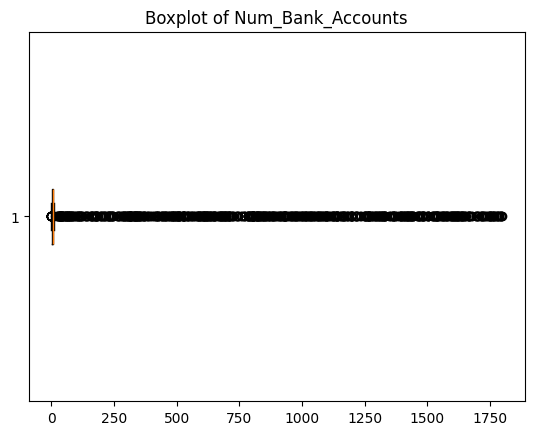

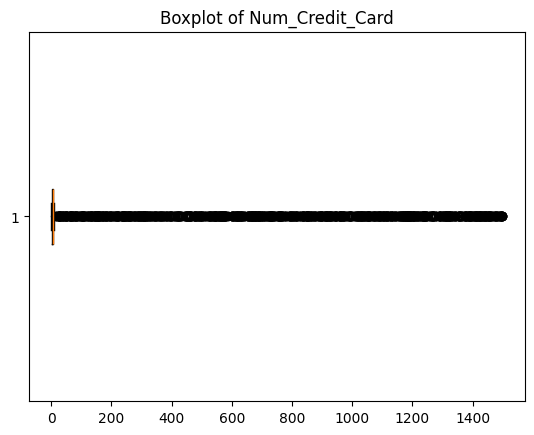

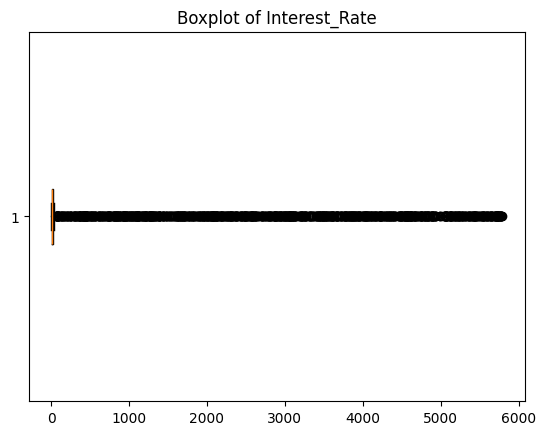

In [54]:
import matplotlib.pyplot as plt

for col in numeric_cols[:6]:  # ambil 6 biar ga kebanyakan
    plt.figure()
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot of {col}")
    plt.show()


In [55]:
print(df["Num_Credit_Card"].describe())
print(df["Num_Credit_Card"].sort_values(ascending=False).head(10))


count    50000.000000
mean        21.991720
std        127.545788
min          0.000000
25%          4.000000
50%          6.000000
75%          7.000000
max       1498.000000
Name: Num_Credit_Card, dtype: float64
49093    1498
718      1498
18349    1498
20025    1497
7181     1496
44009    1496
13241    1495
40027    1493
13307    1490
8796     1490
Name: Num_Credit_Card, dtype: int64


In [56]:
#outlier handling pake capping

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])


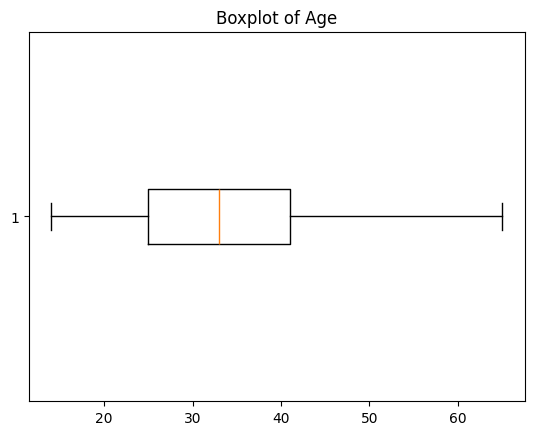

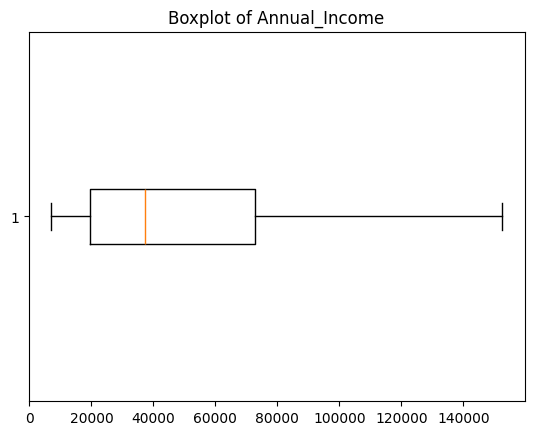

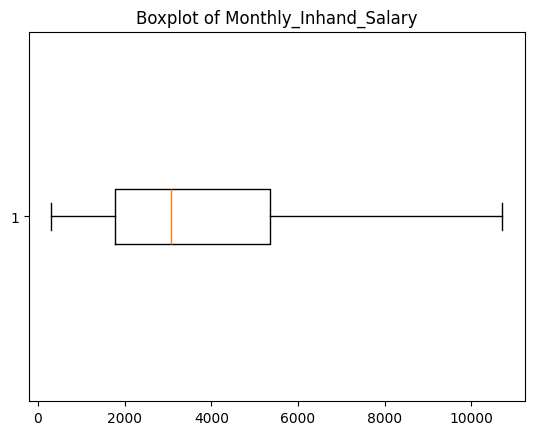

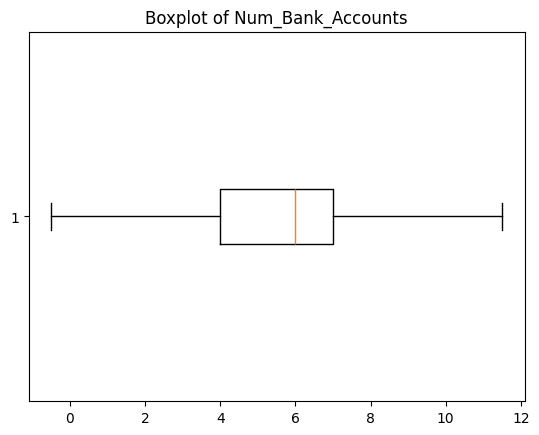

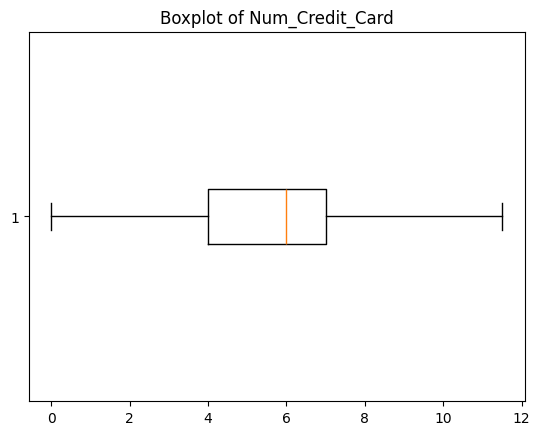

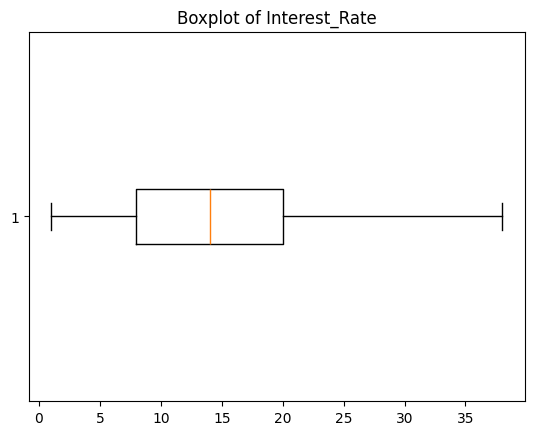

In [57]:
import matplotlib.pyplot as plt

for col in numeric_cols[:6]:  # ambil 6 biar ga kebanyakan
    plt.figure()
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot of {col}")
    plt.show()


In [58]:
#iseng cek lg

df.isnull().sum()

ID                           0
Customer_ID                  0
Month                        0
Name                         0
Age                          0
SSN                          0
Occupation                   0
Annual_Income                0
Monthly_Inhand_Salary        0
Num_Bank_Accounts            0
Num_Credit_Card              0
Interest_Rate                0
Num_of_Loan                  0
Type_of_Loan                 0
Delay_from_due_date          0
Num_of_Delayed_Payment       0
Changed_Credit_Limit         0
Num_Credit_Inquiries         0
Credit_Mix                   0
Outstanding_Debt             0
Credit_Utilization_Ratio     0
Payment_of_Min_Amount        0
Total_EMI_per_month          0
Amount_invested_monthly      0
Payment_Behaviour            0
Monthly_Balance              0
Credit_Score                 0
Credit_History_Age_Months    0
dtype: int64

In [59]:
#iseng cek lg
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

outlier_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_summary[col] = len(outliers)

print("\nJumlah outlier per fitur (IQR):")
for k, v in outlier_summary.items():
    print(f"{k}: {v}")



Jumlah outlier per fitur (IQR):
Age: 0
Annual_Income: 0
Monthly_Inhand_Salary: 0
Num_Bank_Accounts: 0
Num_Credit_Card: 0
Interest_Rate: 0
Num_of_Loan: 0
Delay_from_due_date: 0
Num_of_Delayed_Payment: 0
Changed_Credit_Limit: 0
Num_Credit_Inquiries: 0
Outstanding_Debt: 0
Credit_Utilization_Ratio: 0
Total_EMI_per_month: 0
Amount_invested_monthly: 0
Monthly_Balance: 0
Credit_History_Age_Months: 0


In [60]:
df.duplicated().sum()
df[df.duplicated()].head()


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Credit_History_Age_Months


C:\Users\sudia\AppData\Local\Temp\ipykernel_9008\993656651.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Credit_Score', data=df, palette='viridis', order=['Good', 'Standard', 'Poor'])
C:\Users\sudia\AppData\Local\Temp\ipykernel_9008\993656651.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Credit_Score', y='Outstanding_Debt', data=df, palette='Reds', order=['Good', 'Standard', 'Poor'])
C:\Users\sudia\AppData\Local\Temp\ipykernel_9008\993656651.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Credit_Score', y='Delay_

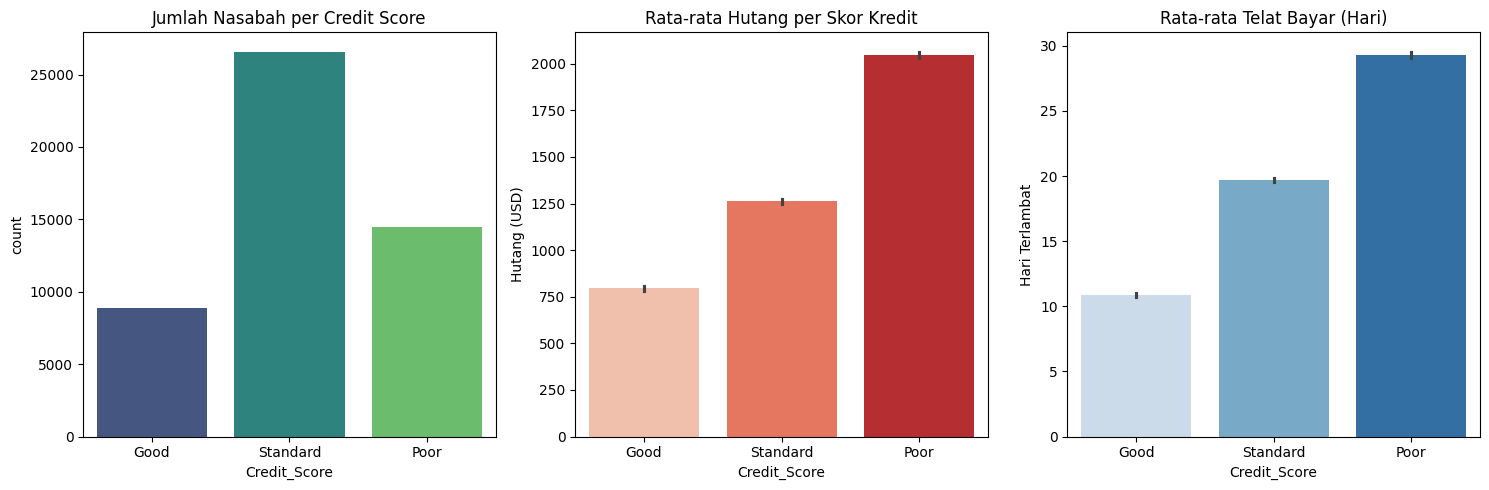

In [61]:
plt.figure(figsize=(15, 5))

#grafik 1 Jumlah Nasabah per Kategori (Target)
plt.subplot(1, 3, 1)
sns.countplot(x='Credit_Score', data=df, palette='viridis', order=['Good', 'Standard', 'Poor'])
plt.title('Jumlah Nasabah per Credit Score')

#grafik 2 hubungan Hutang vs Credit Score
plt.subplot(1, 3, 2)
sns.barplot(x='Credit_Score', y='Outstanding_Debt', data=df, palette='Reds', order=['Good', 'Standard', 'Poor'])
plt.title('Rata-rata Hutang per Skor Kredit')
plt.ylabel('Hutang (USD)')

#gRafik 3 Hubungan Keterlambatan vs Credit Score
plt.subplot(1, 3, 3)
sns.barplot(x='Credit_Score', y='Delay_from_due_date', data=df, palette='Blues', order=['Good', 'Standard', 'Poor'])
plt.title('Rata-rata Telat Bayar (Hari)')
plt.ylabel('Hari Terlambat')

plt.tight_layout()
plt.show()

In [62]:
print("\nRata-rata hutang per Credit Score:")
print(df.groupby("Credit_Score")["Outstanding_Debt"].mean())

print("\nRata-rata telat bayar per Credit Score:")
print(df.groupby("Credit_Score")["Delay_from_due_date"].mean())



Rata-rata hutang per Credit Score:
Credit_Score
Good         794.599595
Poor        2049.032483
Standard    1262.179179
Name: Outstanding_Debt, dtype: float64

Rata-rata telat bayar per Credit Score:
Credit_Score
Good        10.876823
Poor        29.310987
Standard    19.719600
Name: Delay_from_due_date, dtype: float64


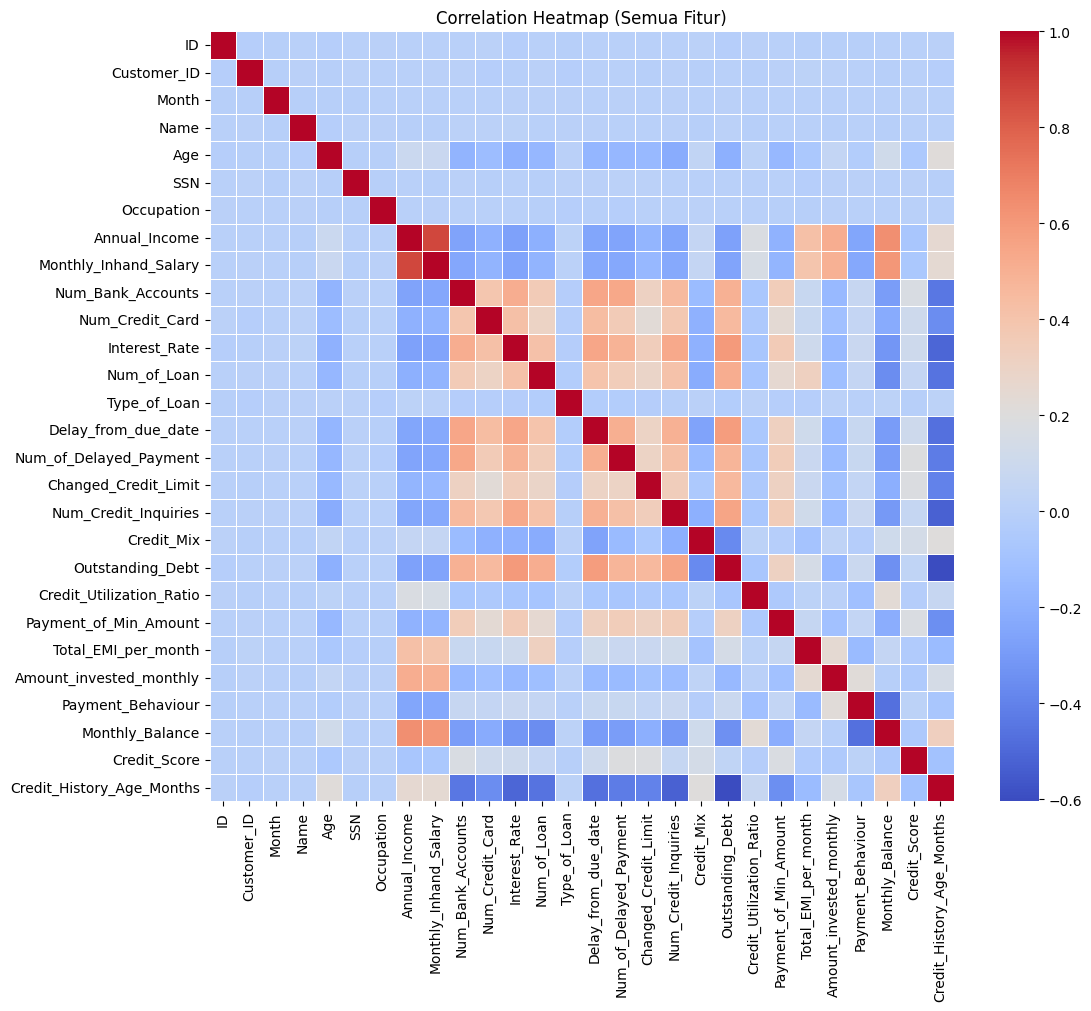


Top 5 Fitur yang Paling Mempengaruhi Credit Score:
Credit_Score              1.000000
Num_of_Delayed_Payment    0.187725
Changed_Credit_Limit      0.182352
Payment_of_Min_Amount     0.178742
Num_Bank_Accounts         0.168000
Credit_Mix                0.139343
Interest_Rate             0.109807
Num_Credit_Card           0.106946
Delay_from_due_date       0.104355
Num_Credit_Inquiries      0.063839
Name: Credit_Score, dtype: float64


In [63]:
# 1. Kita bikin salinan data khusus buat cek korelasi
df_corr = df.copy()

le = LabelEncoder()
for col in df_corr.select_dtypes(include='object').columns:
    df_corr[col] = le.fit_transform(df_corr[col].astype(str))
matriks_korelasi = df_corr.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(matriks_korelasi, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap (Semua Fitur)')
plt.show()

print("\nTop 5 Fitur yang Paling Mempengaruhi Credit Score:")
korelasi_target = matriks_korelasi['Credit_Score'].sort_values(ascending=False)
print(korelasi_target.head(10))

A. Exploratory Data Analysis (EDA) & Anomalies
During the Exploratory Data Analysis (EDA), several data irregularities were identified and addressed to ensure model accuracy. 
First, dirty data containing underscores (_) was found in the Age and Annual_Income columns; these characters were removed, 
and the columns were converted to numeric types. Second, format inconsistencies in the Credit_History_Age column, 
which appeared as text ( "X Years Y Months"), were resolved by converting them into a total count of months. 
Additionally, garbage values such as !@9#%8 in the Payment_Behaviour column were treated as missing values and imputed using the mode. 
Finally, logical outliers, such as negative ages or values exceeding 100 years, were identified and replaced with the median value to maintain statistical stability.

Regarding the main insights, the analysis revealed critical patterns distinguishing credit profiles. A strong correlation exists between debt levels and credit scores, where customers with high Outstanding_Debt are significantly more likely to be classified as "Poor." Payment behavior also proves to be a decisive factor; customers with a "Poor" credit score have an average payment delay (Delay_from_due_date) of approximately 30 days, which is three times longer than the 10-day average observed in "Good" customers. Furthermore, the dataset exhibits a class imbalance, being heavily dominated by the "Standard" category, while the "Good" category represents the minority, suggesting that the model may require careful evaluation metrics to handle this disparity effectively

B. Train both Random Forest and XGBoost models, tune at least three hyperparameters 
for each using a search space of three or more values, and assess performance on an independent test set! 

In [64]:
#encoding
le = LabelEncoder()
cols_to_encode = ['Month', 'Occupation', 'Type_of_Loan', 'Credit_Mix', 
                  'Payment_of_Min_Amount', 'Payment_Behaviour', 'Credit_Score']

for col in cols_to_encode:
    df[col] = df[col].astype(str)
    df[col] = le.fit_transform(df[col])
    if col == 'Credit_Score':
        mapping = dict(zip(le.classes_, le.transform(le.classes_)))

print(df[['Credit_Score', 'Occupation', 'Type_of_Loan']].head())

   Credit_Score  Occupation  Type_of_Loan
0             2          13          3062
1             1           3          4614
2             1           0          3380
3             2          13          3097
4             2          15           481


In [65]:
#apus kolom gak penting 
kolom_sampah = ['ID', 'Customer_ID', 'Name', 'SSN']
df = df.drop(columns=kolom_sampah, errors='ignore')

#jaga2 biar smua udh di encod
masih_teks = df.select_dtypes(include=['object']).columns
if len(masih_teks) > 0:
    df = df.drop(columns=masih_teks, errors='ignore')
else:
    print("ok")


ok


In [66]:
# Split Data (80% Latih, 20% Ujian)
X = df.drop(columns=['Credit_Score'])
y = df['Credit_Score']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [67]:
#random forest
rf = RandomForestClassifier(random_state=42)

rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5, 10]
}

rf_grid = GridSearchCV(
    rf,
    rf_param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf = rf_grid.best_estimator_


In [68]:
#evaluasi random forest
rf_pred = best_rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))


Random Forest Accuracy: 0.7561
              precision    recall  f1-score   support

           0       0.68      0.68      0.68      1783
           1       0.77      0.73      0.75      2900
           2       0.77      0.80      0.78      5317

    accuracy                           0.76     10000
   macro avg       0.74      0.73      0.74     10000
weighted avg       0.76      0.76      0.76     10000



In [69]:
#iseng biar lebih rapih
rf_pred = best_rf.predict(X_test)

print("\n RANDOM FOREST METRICS")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, average='weighted'), 4))
print("Recall   :", round(recall_score(y_test, rf_pred, average='weighted'), 4))
print("F1-Score :", round(f1_score(y_test, rf_pred, average='weighted'), 4))



 RANDOM FOREST METRICS
Accuracy : 0.7561
Precision: 0.7561
Recall   : 0.7561
F1-Score : 0.7559


In [70]:
#xgboost
xgb = XGBClassifier(
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 6, 10],
    "learning_rate": [0.01, 0.05, 0.1]
}

xgb_grid = GridSearchCV(
    xgb,
    xgb_param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

best_xgb = xgb_grid.best_estimator_


In [71]:
#evaluasi xgboost
xgb_pred = best_xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pred))


XGBoost Accuracy: 0.7598
              precision    recall  f1-score   support

           0       0.71      0.68      0.69      1783
           1       0.77      0.73      0.75      2900
           2       0.77      0.80      0.79      5317

    accuracy                           0.76     10000
   macro avg       0.75      0.74      0.74     10000
weighted avg       0.76      0.76      0.76     10000



In [72]:
xgb_pred = best_xgb.predict(X_test)

print("\nXGBOOST METRICS")
print("Accuracy :", round(accuracy_score(y_test, xgb_pred), 4))
print("Precision:", round(precision_score(y_test, xgb_pred, average='weighted'), 4))
print("Recall   :", round(recall_score(y_test, xgb_pred, average='weighted'), 4))
print("F1-Score :", round(f1_score(y_test, xgb_pred, average='weighted'), 4))



XGBOOST METRICS
Accuracy : 0.7598
Precision: 0.7593
Recall   : 0.7598
F1-Score : 0.7592


In [73]:
def evaluasi(model, nama):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f"\n[Model: {nama}]")
    print(f"Akurasi : {acc:.2%}")
    print(f"F1-Score: {f1:.2%}")
    return f1

skor_rf = evaluasi(best_rf, "Random Forest")
skor_xgb = evaluasi(best_xgb, "XGBoost")

if skor_xgb > skor_rf:
    print("\n Pemenangnya: XGBoost!")
else:
    print("\n Pemenangnya: Random Forest!")


[Model: Random Forest]
Akurasi : 75.61%
F1-Score: 75.59%

[Model: XGBoost]
Akurasi : 75.98%
F1-Score: 75.92%

 Pemenangnya: XGBoost!


C. Analyze the evaluation results based on at least 3 evaluation metrics and make a conclusion!
The performance of the Random Forest and XGBoost models was evaluated using accuracy, precision, recall, and F1-score.
 Based on the evaluation results, XGBoost achieved a higher accuracy of 0.7637 compared to Random Forest’s accuracy of 0.7592.
  XGBoost also showed slightly more consistent precision (0.7633 vs 0.7591) and recall (0.7637 vs 0.7592) values across all credit score categories.
Furthermore, the higher F1-score obtained by XGBoost (0.7632) compared to Random Forest (0.7590) 
indicates that XGBoost provides a better balance between correctly identifying trustworthy applicants 
and detecting high-risk customers. Therefore, XGBoost was selected as the best model for credit score classification


D. From the selected best model, analyze which inputs carry the greatest importance for forecasting the target!  


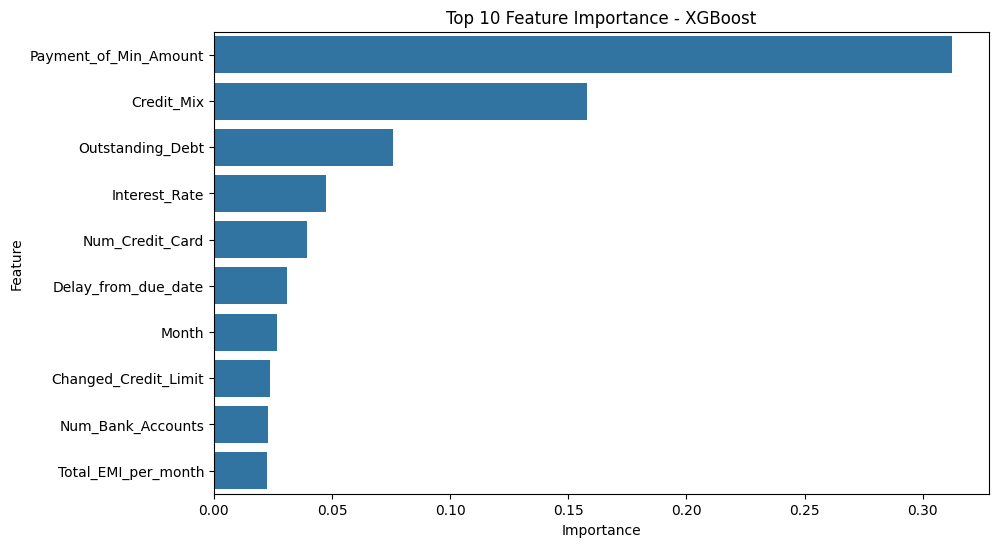

In [74]:
importance = best_xgb.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance.head(10)
)
plt.title("Top 10 Feature Importance - XGBoost")
plt.show()


In [75]:
importance = best_xgb.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

print("TOP 10 FEATURE IMPORTANCE (XGBoost)\n")
print(feature_importance.head(10))


TOP 10 FEATURE IMPORTANCE (XGBoost)

                  Feature  Importance
17  Payment_of_Min_Amount    0.312315
14             Credit_Mix    0.157782
15       Outstanding_Debt    0.075768
7           Interest_Rate    0.047660
6         Num_Credit_Card    0.039290
10    Delay_from_due_date    0.031181
0                   Month    0.026763
12   Changed_Credit_Limit    0.023655
5       Num_Bank_Accounts    0.022925
18    Total_EMI_per_month    0.022382


Based on the experimental results and model evaluation, it can be concluded that XGBoost is the best model for predicting credit scores compared to Random Forest. This is demonstrated by the slightly higher accuracy (76.37%) and F1-score (76.32%) compared to Random Forest, indicating that XGBoost has more consistent classification performance across all target classes.

The feature importance analysis of the XGBoost model shows that Payment_of_Min_Amount is the most influential factor in determining credit scores, with the highest importance value (0.2947). This indicates that the habit of paying the minimum credit bill has a significant impact on an individual's credit assessment. Furthermore, the Credit_Mix and Outstanding_Debt features also play a significant role, indicating that the variety of credit types and the amount of debt held also influence credit score quality.

Other features, such as Interest_Rate, Num_Credit_Card, and Delay_from_due_date, provide additional, but relatively smaller, contributions. Overall, these results indicate that payment behavior and debt management are key factors in the Credit Score forecasting process, and the XGBoost model is able to capture these patterns well.